# TP2 – Aprendizaje Automático 1
**Agustín Delgado**

Actividades «Para pensar» y Parte 5 del notebook de clasificación con redes neuronales.


## Para pensar – Pingüinos

**Exploración de especies.** Utilizo las medidas de los pingüinos para comparar cómo se separan las tres especies.


In [1]:
# ── Librerías básicas de datos y gráficos ──
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# ── Utilidades de scikit-learn para preparar datos y validar ──
from sklearn.model_selection import (
    train_test_split, cross_val_score, validation_curve,
    RandomizedSearchCV, StratifiedKFold
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning

# ── Los modelos protagonistas: redes neuronales ──
from sklearn.neural_network import MLPClassifier

# ── Modelos de referencia (para comparar) ──
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# ── Métricas ──
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
)

# ── Para interpretar un modelo "caja negra" ──
from sklearn.inspection import permutation_importance

# ── Distribución para la búsqueda aleatoria de hiperparámetros ──
from scipy.stats import loguniform

# ── Configuración general ──
SEMILLA = 42                       # Fijamos la semilla para que los resultados sean reproducibles
sns.set_theme(style="whitegrid")   # Estilo de gráficos
pd.set_option("display.precision", 3)

# Las redes neuronales lanzan muchos avisos de "convergencia" cuando entrenamos decenas de modelos
# (por ejemplo, en las búsquedas de hiperparámetros). Para no llenar la pantalla los ocultamos,
# Mantengo la salida sin avisos repetidos.
warnings.filterwarnings("ignore", category=ConvergenceWarning)




In [2]:
url_pinguinos = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df_ping = pd.read_csv(url_pinguinos)

print(f"Dimensiones: {df_ping.shape}")
df_ping.head()

Dimensiones: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
# Valores faltantes y distribución de las clases
print("Valores faltantes por columna:")
print(df_ping.isna().sum())

print("\nDistribución de especies:")
print(df_ping["species"].value_counts())

Valores faltantes por columna:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Distribución de especies:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


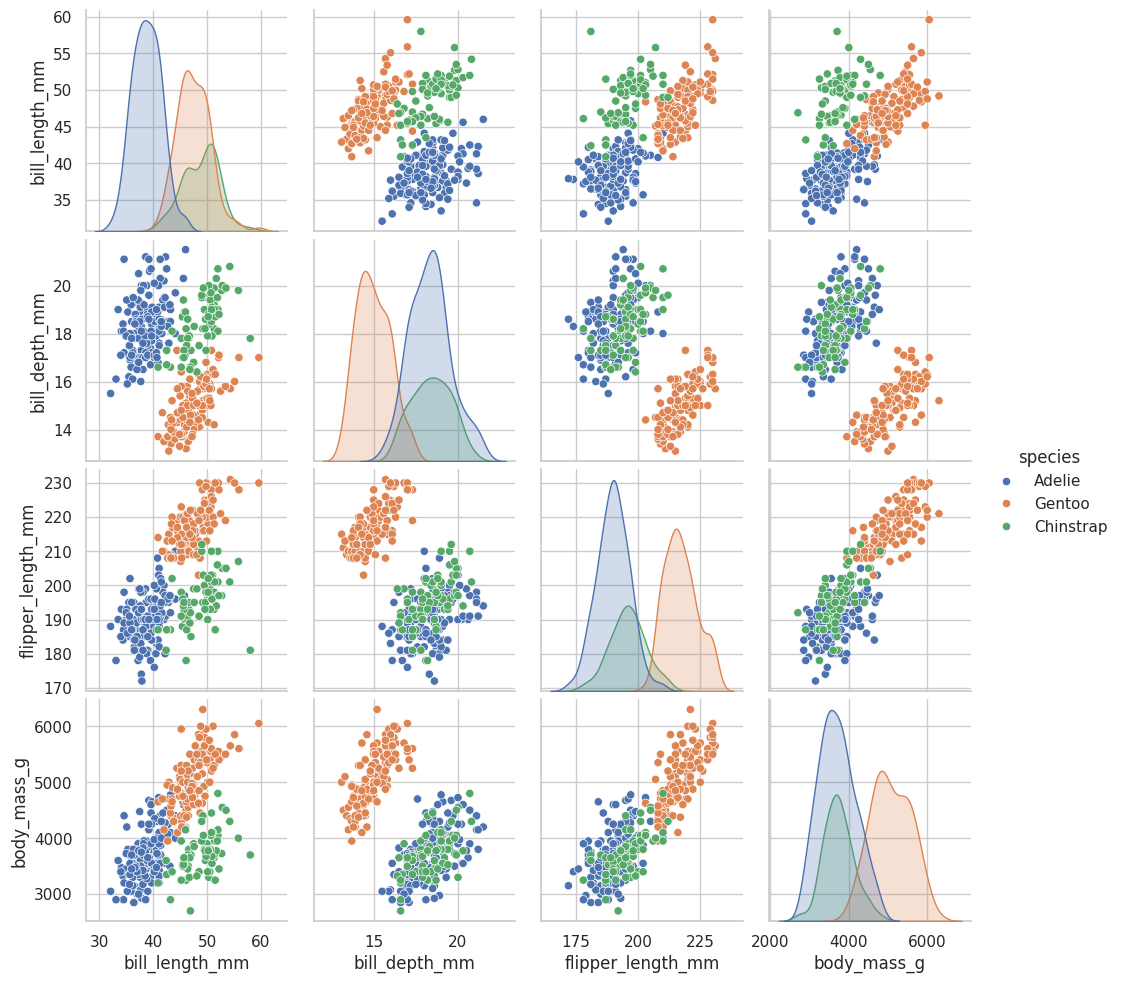

In [4]:
# Relación entre variables, coloreando por especie
sns.pairplot(df_ping, hue="species", vars=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"])
plt.show()

**Para pensar 1. ¿Qué variables separan mejor las especies? ¿Es un problema difícil?**

Por los gráficos, las medidas del pico son las que mejor separan las especies. También se nota que *Gentoo* suele tener mayor tamaño y aletas más largas. Creo que no es un problema muy difícil para un clasificador, aunque hay algunas observaciones que se superponen.


In [5]:
X_p = df_ping.drop(columns=["species"])
y_p = df_ping["species"]

X_ent_p, X_prueba_p, y_ent_p, y_prueba_p = train_test_split(
    X_p, y_p,
    test_size=0.2,
    random_state=SEMILLA,
    stratify=y_p          # mantiene las proporciones de cada clase
)

print("Proporción de clases en entrenamiento:")
print(y_ent_p.value_counts(normalize=True).round(3))

Proporción de clases en entrenamiento:
species
Adelie       0.444
Gentoo       0.360
Chinstrap    0.196
Name: proportion, dtype: float64


In [6]:
cols_num_p = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cols_cat_p = ["island", "sex"]

preprocesador_clf = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())
    ]), cols_num_p),
    ("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),     # moda para categóricas
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cols_cat_p)
])

In [7]:
# Función para evaluar clasificadores
def evaluar_clasificacion(modelo, X_ent, y_ent, X_prueba, y_prueba, nombre):
    pred_ent = modelo.predict(X_ent)
    pred_prueba = modelo.predict(X_prueba)
    return {
        "modelo": nombre,
        "accuracy_entrenamiento": accuracy_score(y_ent, pred_ent),
        "accuracy_prueba": accuracy_score(y_prueba, pred_prueba),
        "F1_macro_entrenamiento": f1_score(y_ent, pred_ent, average="macro"),
        "F1_macro_prueba": f1_score(y_prueba, pred_prueba, average="macro"),
    }

resultados_clf = []

# Baseline 1: Dummy
dummy_clf = Pipeline([("prep", preprocesador_clf), ("modelo", DummyClassifier(strategy="most_frequent"))])
dummy_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(dummy_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "Dummy (clase mayoritaria)"))

# Baseline 2: Regresión logística
logit_clf = Pipeline([("prep", preprocesador_clf), ("modelo", LogisticRegression(max_iter=1000))])
logit_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(logit_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "Regresión logística"))

# Nuestra primera red neuronal para clasificar
mlp_clf = Pipeline([
    ("prep", preprocesador_clf),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        max_iter=2000,
        random_state=SEMILLA
    ))
])
mlp_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(mlp_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "MLP inicial (32,16)"))

pd.DataFrame(resultados_clf)

,modelo,accuracy_entrenamiento,accuracy_prueba,F1_macro_entrenamiento,F1_macro_prueba
0,Dummy (clase mayoritaria),0.444,0.435,0.205,0.202
1,Regresión logística,0.993,1.000,0.992,1.000
2,"MLP inicial (32,16)",1.000,0.986,1.000,0.983


**Para pensar 2. ¿Por qué no mirar solamente el accuracy?**

Porque indica cuántas predicciones fueron correctas, pero no muestra en qué clases se equivoca el modelo. Si una clase es mayoritaria, el accuracy puede ser alto aun cuando el modelo clasifique mal las demás. Por eso también comparé F1 y la matriz de confusión.


              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       0.93      1.00      0.97        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.98      0.99      0.98        69
weighted avg       0.99      0.99      0.99        69



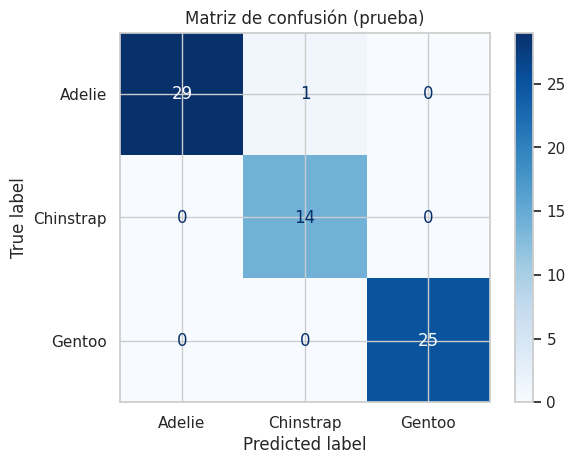

In [8]:
pred_p = mlp_clf.predict(X_prueba_p)

print(classification_report(y_prueba_p, pred_p))

ConfusionMatrixDisplay.from_estimator(mlp_clf, X_prueba_p, y_prueba_p, cmap="Blues")
plt.title("Matriz de confusión (prueba)")
plt.show()

In [11]:
# Distribuciones / listas de valores a explorar
distribuciones = {
    "mlp__hidden_layer_sizes": [(8,), (16,), (32,), (64,), (32, 16), (64, 32)],
    "mlp__activation": ["relu", "tanh", "logistic"],
    "mlp__solver": ["adam", "lbfgs"],
    "mlp__alpha": loguniform(1e-5, 1e0),                # entre 0.00001 y 1
    "mlp__learning_rate_init": loguniform(1e-4, 1e-1),  # (solo afecta al solver "adam")
}

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

busqueda_clf = RandomizedSearchCV(
    estimator=mlp_clf,
    param_distributions=distribuciones,
    n_iter=20,                  # cantidad de combinaciones aleatorias a probar
    cv=validacion,
    scoring="f1_macro",
    n_jobs=2,
    random_state=SEMILLA,
    verbose=1
)

busqueda_clf.fit(X_ent_p, y_ent_p)

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_clf.best_params_.items():
    print(f"  {parametro}: {valor}")
print(f"\nMejor F1 macro en validación cruzada: {busqueda_clf.best_score_:.3f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits



Mejores hiperparámetros:
  mlp__activation: tanh
  mlp__alpha: 2.8381292701126715e-05
  mlp__hidden_layer_sizes: (64, 32)
  mlp__learning_rate_init: 0.0003972110727381913
  mlp__solver: adam

Mejor F1 macro en validación cruzada: 0.997


In [13]:
mejor_clf = busqueda_clf.best_estimator_

resultados_clf.append(evaluar_clasificacion(mejor_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "MLP optimizado (RandomSearch)"))
pd.DataFrame(resultados_clf).set_index("modelo")

,accuracy_entrenamiento,accuracy_prueba,F1_macro_entrenamiento,F1_macro_prueba
modelo,,,,
Dummy (clase mayoritaria),0.444,0.435,0.205,0.202
Regresión logística,0.993,1.000,0.992,1.000
"MLP inicial (32,16)",1.000,0.986,1.000,0.983
MLP optimizado (RandomSearch),1.000,0.986,1.000,0.983


**Para pensar 3. ¿Qué tan difícil fue clasificar los pingüinos? ¿Mejoró la red? ¿Hay margen para ajustar?**

Fue un problema bastante sencillo: la regresión logística obtuvo un F1 macro de **1,000** y la red inicial de **0,983** en prueba. Luego del ajuste, la red quedó en **0,983**. Como los resultados ya eran muy buenos, había poco margen de mejora; una red más compleja no fue necesariamente mejor.


## Parte 5 – Actividades

### Actividad 2. Clasificación: supervivencia en el Titanic

Voy a trabajar con `survived` (1 = sobrevivió, 0 = no sobrevivió) y comparar una red neuronal con dos modelos de referencia.


In [15]:
url_titanic = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df_tit = pd.read_csv(url_titanic)

df_tit.head()

#### 2.1 Exploración y variables

Seleccioné `pclass`, `age`, `sibsp`, `parch`, `fare`, `sex` y `embarked`. Excluí `alive` porque revela directamente el resultado y produciría fuga de información.


Pasajeros: 891

Proporción de supervivencia:
          cantidad  proporción
survived                      
0              549       0.616
1              342       0.384

Faltantes de las variables seleccionadas:
          faltantes
pclass            0
age             177
sibsp             0
parch             0
fare              0
sex               0
embarked          2

Tasa de supervivencia por sexo y clase (media de survived):
pclass      1      2      3
sex                        
female  0.968  0.921  0.500
male    0.369  0.157  0.135


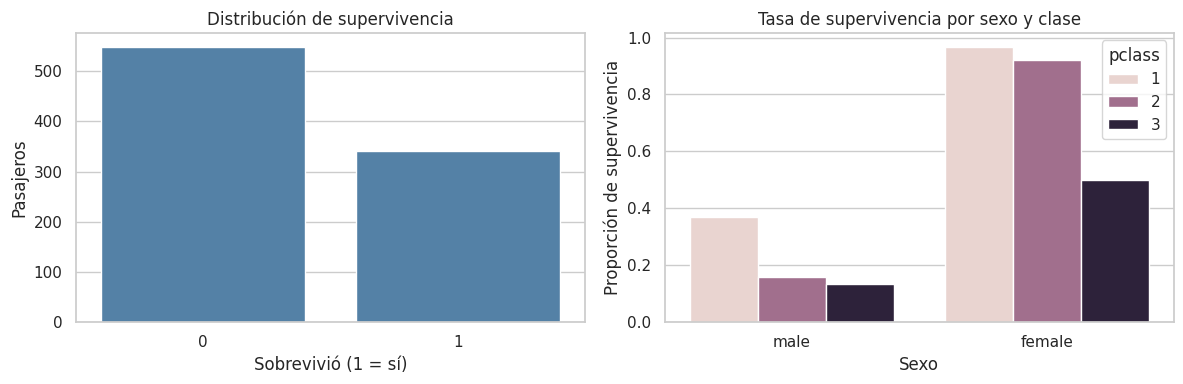

In [16]:
# Actividad 2.1 · Variables elegidas y exploración (sin fuga de información)
cols_num_t = ["pclass", "age", "sibsp", "parch", "fare"]
cols_cat_t = ["sex", "embarked"]
cols_t = cols_num_t + cols_cat_t

X_t = df_tit[cols_t].copy()  # 'alive' y las redundantes quedan EXCLUIDAS
y_t = df_tit["survived"].astype(int)

print(f"Pasajeros: {len(df_tit)}")
print("\nProporción de supervivencia:")
print(pd.DataFrame({"cantidad": y_t.value_counts().sort_index(),
                    "proporción": y_t.value_counts(normalize=True).sort_index().round(3)}))
print("\nFaltantes de las variables seleccionadas:")
print(X_t.isna().sum().to_frame("faltantes"))
print("\nTasa de supervivencia por sexo y clase (media de survived):")
print(df_tit.pivot_table(index="sex", columns="pclass", values="survived", aggfunc="mean").round(3))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df_tit, x="survived", ax=ejes[0], color="steelblue")
ejes[0].set(title="Distribución de supervivencia", xlabel="Sobrevivió (1 = sí)", ylabel="Pasajeros")
sns.barplot(data=df_tit, x="sex", y="survived", hue="pclass", errorbar=None, ax=ejes[1])
ejes[1].set(title="Tasa de supervivencia por sexo y clase", xlabel="Sexo", ylabel="Proporción de supervivencia")
plt.tight_layout()
plt.show()


**Resultado.** De los 891 pasajeros, el **38,4 %** sobrevivió. Encontré 177 valores faltantes en `age` y 2 en `embarked`. La supervivencia fue mayor entre las mujeres y entre los pasajeros de primera clase.


#### 2.2 División y preprocesamiento

Separé el 80 % para entrenamiento y el 20 % para prueba, manteniendo la proporción de las clases. Imputé los valores faltantes y preparé las variables numéricas y categóricas.


In [17]:
# Actividad 2.2 · División estratificada y preprocesamiento dentro de Pipeline
X_ent_t, X_prueba_t, y_ent_t, y_prueba_t = train_test_split(
    X_t, y_t, test_size=0.20, stratify=y_t, random_state=SEMILLA
)

preprocesador_t = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())
    ]), cols_num_t),
    ("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cols_cat_t)
])

print("Entrenamiento:", X_ent_t.shape, "| Prueba:", X_prueba_t.shape)
print("Proporción de clase 1 — global / entrenamiento / prueba:",
      round(y_t.mean(), 3), round(y_ent_t.mean(), 3), round(y_prueba_t.mean(), 3))
print("El preprocesador se ajustará únicamente con el conjunto de entrenamiento.")


Entrenamiento: (712, 7) | Prueba: (179, 7)
Proporción de clase 1 — global / entrenamiento / prueba: 0.384 0.383 0.385
El preprocesador se ajustará únicamente con el conjunto de entrenamiento.


#### 2.3 Comparación de modelos

Entrené un modelo de mayoría (Dummy), una regresión logística y una red neuronal MLP para comparar accuracy y F1 macro.


In [18]:
# Actividad 2.3 · Dummy, regresión logística y primera red neuronal
modelos_t = {
    "Dummy (mayoría)": Pipeline([
        ("prep", preprocesador_t),
        ("modelo", DummyClassifier(strategy="most_frequent"))
    ]),
    "Regresión logística": Pipeline([
        ("prep", preprocesador_t),
        ("modelo", LogisticRegression(max_iter=1000, random_state=SEMILLA))
    ]),
    "MLP inicial (32,16)": Pipeline([
        ("prep", preprocesador_t),
        ("mlp", MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu",
                              alpha=0.0001, max_iter=1000, random_state=SEMILLA))
    ])
}
resultados_t = []
for nombre, modelo in modelos_t.items():
    modelo.fit(X_ent_t, y_ent_t)
    resultados_t.append(evaluar_clasificacion(
        modelo, X_ent_t, y_ent_t, X_prueba_t, y_prueba_t, nombre
    ))

mlp_t = modelos_t["MLP inicial (32,16)"]
logit_t = modelos_t["Regresión logística"]
tabla_t = pd.DataFrame(resultados_t).set_index("modelo")
display(tabla_t.round(3))


,accuracy_entrenamiento,accuracy_prueba,F1_macro_entrenamiento,F1_macro_prueba
modelo,,,,
Dummy (mayoría),0.617,0.615,0.381,0.381
Regresión logística,0.808,0.804,0.793,0.786
"MLP inicial (32,16)",0.899,0.788,0.891,0.773


**Resultado.** En prueba, el MLP inicial obtuvo **78,8 % de accuracy** y **0,773 de F1 macro**. La regresión logística obtuvo **0,786 de F1 macro**, por lo que la red no fue la mejor en esta comparación.


#### 2.4 Análisis de errores

Revisé el reporte de clasificación y la matriz de confusión del MLP.


Reporte de clasificación — MLP inicial:
                   precision    recall  f1-score   support

No sobrevivió (0)       0.82      0.85      0.83       110
   Sobrevivió (1)       0.74      0.70      0.72        69

         accuracy                           0.79       179
        macro avg       0.78      0.77      0.77       179
     weighted avg       0.79      0.79      0.79       179



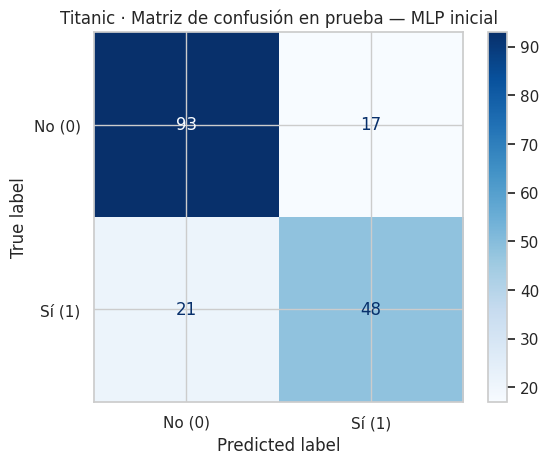

Falsos negativos (sobrevivió, predije no): 21
Falsos positivos (no sobrevivió, predije sí): 17
Clase real 1: 69 | Clase real 0: 110
Recall clase 1: 0.696


In [19]:
# Actividad 2.4 · Matriz de confusión y tipos de error
from sklearn.metrics import confusion_matrix, precision_score, recall_score

pred_t = mlp_t.predict(X_prueba_t)
print("Reporte de clasificación — MLP inicial:")
print(classification_report(y_prueba_t, pred_t, labels=[0, 1],
                            target_names=["No sobrevivió (0)", "Sobrevivió (1)"],
                            zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_prueba_t, pred_t, labels=[0, 1], cmap="Blues",
    display_labels=["No (0)", "Sí (1)"]
)
plt.title("Titanic · Matriz de confusión en prueba — MLP inicial")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_prueba_t, pred_t, labels=[0, 1]).ravel()
print(f"Falsos negativos (sobrevivió, predije no): {fn}")
print(f"Falsos positivos (no sobrevivió, predije sí): {fp}")
print(f"Clase real 1: {int((y_prueba_t == 1).sum())} | Clase real 0: {int((y_prueba_t == 0).sum())}")
print("Recall clase 1:", round(recall_score(y_prueba_t, pred_t, zero_division=0), 3))


**Resultado.** El modelo cometió **21 falsos negativos** (pasajeros que sobrevivieron, pero clasificó como no sobrevivientes) y **17 falsos positivos**. Se equivocó más al detectar a quienes sobrevivieron. La gravedad de cada error depende del uso real del modelo: por ejemplo, si sirve para priorizar asistencia, dejar sin ayuda a alguien que la necesita podría ser más grave.


#### 2.5 Ajuste de hiperparámetros

Probé diferentes capas, funciones de activación y regularización con `RandomizedSearchCV` y validación cruzada de cinco particiones.


In [20]:
# Actividad 2.5 · RandomizedSearchCV con cinco particiones estratificadas
cv_t = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
distribuciones_t = {
    "mlp__hidden_layer_sizes": [(8,), (16,), (32,), (32, 16), (64, 32)],
    "mlp__alpha": loguniform(1e-5, 10),
    "mlp__activation": ["relu", "tanh", "logistic"]
}

# Mismo protocolo CV para el MLP inicial y las alternativas:
cv_inicial_t = cross_val_score(mlp_t, X_ent_t, y_ent_t, cv=cv_t,
                               scoring="f1_macro", n_jobs=2)
busqueda_t = RandomizedSearchCV(
    estimator=mlp_t, param_distributions=distribuciones_t,
    n_iter=15, cv=cv_t, scoring="f1_macro", n_jobs=2,
    random_state=SEMILLA, refit=True, verbose=0
)
busqueda_t.fit(X_ent_t, y_ent_t)  # Nunca se ajusta usando prueba
mejor_t = busqueda_t.best_estimator_

resultados_t.append(evaluar_clasificacion(
    mejor_t, X_ent_t, y_ent_t, X_prueba_t, y_prueba_t,
    "MLP optimizado (RandomSearch)"
))
tabla_t = pd.DataFrame(resultados_t).set_index("modelo")

print("Mejores hiperparámetros:", busqueda_t.best_params_)
print(f"MLP inicial — F1 macro CV: {cv_inicial_t.mean():.3f} ± {cv_inicial_t.std():.3f}")
print(f"MLP optimizado — F1 macro CV: {busqueda_t.best_score_:.3f} ± "
      f"{busqueda_t.cv_results_['std_test_score'][busqueda_t.best_index_]:.3f}")
print(f"Diferencia CV: {busqueda_t.best_score_ - cv_inicial_t.mean():+.3f}")
print("\nResultados en entrenamiento y prueba:")
display(tabla_t.round(3))
print("\nCinco configuraciones mejor ubicadas en validación cruzada:")
res_search_t = pd.DataFrame(busqueda_t.cv_results_)
display(res_search_t.sort_values('rank_test_score')[
    ['param_mlp__hidden_layer_sizes', 'param_mlp__activation', 'param_mlp__alpha',
     'mean_test_score', 'std_test_score', 'rank_test_score']].head().round(3))


Mejores hiperparámetros: {'mlp__activation': 'relu', 'mlp__alpha': np.float64(0.040428727350273294), 'mlp__hidden_layer_sizes': (32,)}
MLP inicial — F1 macro CV: 0.789 ± 0.022
MLP optimizado — F1 macro CV: 0.801 ± 0.025
Diferencia CV: +0.011

Resultados en entrenamiento y prueba:


,accuracy_entrenamiento,accuracy_prueba,F1_macro_entrenamiento,F1_macro_prueba
modelo,,,,
Dummy (mayoría),0.617,0.615,0.381,0.381
Regresión logística,0.808,0.804,0.793,0.786
"MLP inicial (32,16)",0.899,0.788,0.891,0.773
MLP optimizado (RandomSearch),0.858,0.793,0.845,0.773



Cinco configuraciones mejor ubicadas en validación cruzada:


,param_mlp__hidden_layer_sizes,param_mlp__activation,param_mlp__alpha,mean_test_score,std_test_score,rank_test_score
3,"(32,)",relu,0.040,0.801,0.025,1
1,"(16,)",relu,0.038,0.799,0.018,2
6,"(16,)",relu,0.051,0.799,0.018,2
7,"(8,)",tanh,0.000,0.798,0.018,4
5,"(32, 16)",tanh,0.000,0.798,0.035,5


**Resultado.** En validación cruzada, el F1 macro pasó de **0,789** a **0,801**; la mejora fue pequeña frente a la variación entre particiones. En prueba se mantuvo en **0,773**, así que no encontré una mejora clara.


#### 2.6 Importancia de variables y umbrales

Calculé la importancia por permutación y comparé precisión y recall de la clase «sobrevivió» con umbrales de 0,3, 0,5 y 0,7.


,variable,caida_F1_macro_media,desvio
5,sex,0.195,0.028
0,pclass,0.043,0.018
1,age,0.031,0.017
4,fare,0.028,0.018
2,sibsp,0.028,0.013
3,parch,0.024,0.012
6,embarked,0.008,0.011


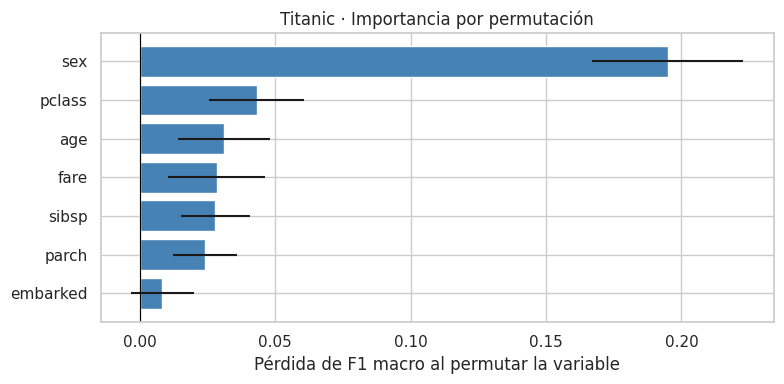

Precisión y recall para la clase 'sobrevivió' (1):


,umbral,precision_clase_1,recall_clase_1,predichos_sobrevivientes
0,0.3,0.699,0.841,83
1,0.5,0.786,0.638,56
2,0.7,0.867,0.565,45


In [21]:
# Actividad 2.6(a) · Importancia por permutación (sobre los datos de prueba)
imp_t = permutation_importance(mejor_t, X_prueba_t, y_prueba_t,
                               n_repeats=30, random_state=SEMILLA,
                               scoring="f1_macro", n_jobs=2)
tabla_imp_t = pd.DataFrame({
    "variable": X_prueba_t.columns,
    "caida_F1_macro_media": imp_t.importances_mean,
    "desvio": imp_t.importances_std
}).sort_values("caida_F1_macro_media", ascending=False)
display(tabla_imp_t.round(3))

orden_imp_t = tabla_imp_t.sort_values("caida_F1_macro_media")
plt.figure(figsize=(8, 4))
plt.barh(orden_imp_t["variable"], orden_imp_t["caida_F1_macro_media"],
         xerr=orden_imp_t["desvio"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Titanic · Importancia por permutación")
plt.xlabel("Pérdida de F1 macro al permutar la variable")
plt.tight_layout()
plt.show()

# Actividad 2.6(b) · Precisión / recall para tres umbrales
idx_clase_1 = list(mejor_t.classes_).index(1)
proba_supervivencia_t = mejor_t.predict_proba(X_prueba_t)[:, idx_clase_1]
res_umbrales_t = []
for umbral in [0.3, 0.5, 0.7]:
    pred_umbral = (proba_supervivencia_t >= umbral).astype(int)
    res_umbrales_t.append({
        "umbral": umbral,
        "precision_clase_1": precision_score(y_prueba_t, pred_umbral, zero_division=0),
        "recall_clase_1": recall_score(y_prueba_t, pred_umbral, zero_division=0),
        "predichos_sobrevivientes": int(pred_umbral.sum())
    })
tabla_umbrales_t = pd.DataFrame(res_umbrales_t)
print("Precisión y recall para la clase 'sobrevivió' (1):")
display(tabla_umbrales_t.round(3))


**Resultado.** Las variables más importantes fueron `sex` y `pclass`, como sugería la exploración. Al subir el umbral, la **precisión** aumentó de **0,699** a **0,867**, pero el **recall** bajó de **0,841** a **0,565**: se identifican menos sobrevivientes, aunque las predicciones positivas son más precisas.


### Actividad 3. Curva de validación

Probé distintos valores de `alpha` para observar si la red se sobreajusta o se queda corta al aprender.


,alpha,accuracy_entrenamiento,accuracy_validacion,gap_ent_val,sd_validacion
0,0.000,0.863,0.820,0.043,0.021
1,0.000,0.863,0.820,0.043,0.022
2,0.001,0.864,0.822,0.043,0.023
3,0.010,0.861,0.822,0.039,0.020
4,0.100,0.856,0.816,0.040,0.022
5,1.000,0.843,0.829,0.014,0.018
6,10.000,0.813,0.802,0.011,0.007


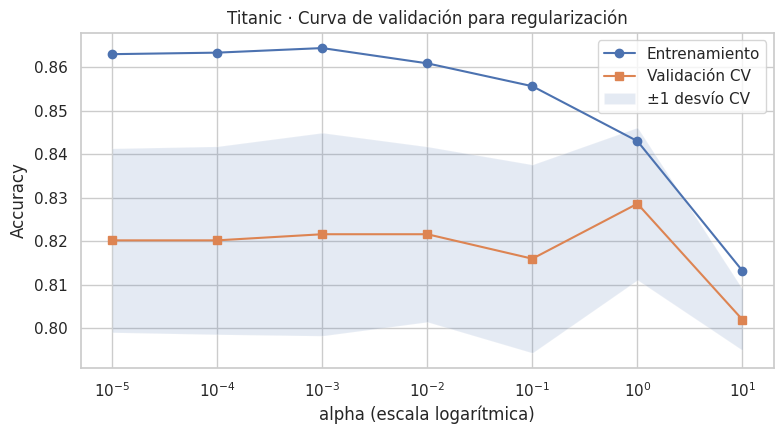

Mejor alpha en la curva (accuracy): 1
Alpha encontrado en RandomSearch (F1 macro): 0.040429
Es esperable que difieran: las métricas de selección no son las mismas.


In [22]:
# Actividad 3 · Curva de validación para alpha (solo entrenamiento)
valores_alpha = np.array([1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0])
train_s, val_s = validation_curve(
    estimator=clone(mejor_t), X=X_ent_t, y=y_ent_t,
    param_name="mlp__alpha", param_range=valores_alpha,
    cv=cv_t, scoring="accuracy", n_jobs=2
)
media_ent, sd_ent = train_s.mean(axis=1), train_s.std(axis=1)
media_val, sd_val = val_s.mean(axis=1), val_s.std(axis=1)
curva_alpha_t = pd.DataFrame({
    "alpha": valores_alpha,
    "accuracy_entrenamiento": media_ent,
    "accuracy_validacion": media_val,
    "gap_ent_val": media_ent - media_val,
    "sd_validacion": sd_val
})
display(curva_alpha_t.round(3))

plt.figure(figsize=(8, 4.5))
plt.semilogx(valores_alpha, media_ent, "o-", label="Entrenamiento")
plt.semilogx(valores_alpha, media_val, "s-", label="Validación CV")
plt.fill_between(valores_alpha, media_val - sd_val, media_val + sd_val,
                 alpha=0.15, label="±1 desvío CV")
plt.xlabel("alpha (escala logarítmica)")
plt.ylabel("Accuracy")
plt.title("Titanic · Curva de validación para regularización")
plt.legend()
plt.tight_layout()
plt.show()

alpha_curva_t = float(valores_alpha[media_val.argmax()])
alpha_busqueda_t = float(busqueda_t.best_params_["mlp__alpha"])
print(f"Mejor alpha en la curva (accuracy): {alpha_curva_t:g}")
print(f"Alpha encontrado en RandomSearch (F1 macro): {alpha_busqueda_t:.5g}")
print("Es esperable que difieran: las métricas de selección no son las mismas.")


**Resultado.** Con valores pequeños de `alpha` vi señales de **sobreajuste**: el resultado en entrenamiento fue mejor que el de validación. Con `alpha = 10` aparecieron señales de **subajuste**. Elegiría **`alpha = 1`** por su mejor accuracy medio de validación. No coincidió con la búsqueda aleatoria (≈ 0,0404), que había optimizado F1 macro.


### Actividad 4. Reflexión final

**4. ¿Por qué en pingüinos casi no cambió el resultado al ajustar el modelo?**

Porque las tres especies se distinguen bastante bien con las variables disponibles y los modelos iniciales ya tenían muy buenos resultados. El ajuste sería más importante con datos más complejos o cuando un modelo tiene sobreajuste o subajuste.

**5. ¿Por qué no alcanza con mirar el accuracy?**

Por ejemplo, si solo el 5 % de los pacientes tiene una enfermedad, un modelo que predice siempre «sano» alcanza el 95 % de accuracy, pero no detecta a ninguna persona enferma. Por eso también hace falta revisar recall, precisión y F1.


### Conclusión

En este TP aprendí a preparar datos y comparar modelos de clasificación, incluyendo una red neuronal. También comprobé que ajustar hiperparámetros no siempre mejora los resultados y que es importante revisar los errores, no solamente el porcentaje de aciertos.
